In [ ]:
%load_ext autoreload
%autoreload 2

%matplotlib widget
import json
import os
import pickle as pkl
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import clear_output
from loguru import logger
from core.inference import uncrop_predictions
from tqdm.notebook import tqdm

from classification import lesion_analysis as lesion_dx
from core.dataset import Dataset
from core.experiment import Experiment
from helpers.parallel import BetterPool
from helpers.shell_interface import open_itksnap_workspace_cmd
from helpers.utils import dice_score, get_prl_indices
from scripts.compile_run_metrics import EXPERIMENT_KEYS, load_or_cache_run


In [ ]:
def get_infer_path(dataset, test_case, experiment_name) -> Path:
    case_dir = dataset.lesion_dir(test_case)
    matches = list(case_dir.glob(f"*{experiment_name.replace('/','_')}.nii.gz"))
    if len(matches) > 1:
        logger.warning(f"Found more than 1 case: {','.join(matches)}, returning the first")
    return matches[0]

    
def find_inference(search_path, experiment_name) -> Path:
    matches = list(search_path.glob(f"*{experiment_name.replace('/','_')}.nii.gz"))
    if len(matches) > 1:
        logger.warning(f"Found more than 1 case: {','.join(matches)}, returning the first")
    return matches[0]

In [14]:
dataset_name = "roi_train2"
dataset = Dataset(dataset_name)

experiment_key, run_name = "stage6", "run1"
experiment_name = f"{EXPERIMENT_KEYS[experiment_key]}/{run_name}"
# experiment_name = "sweep_dicecewts/run1"
# experiment_name = "test_dicece_lambda/run1"
experiment = Experiment.from_run_dir(experiment_name, dataset)

expand_xy: int = experiment.preprocess_config.expand_xy
expand_z: int = experiment.preprocess_config.expand_z
images: tuple[str, ...] = experiment.preprocess_config.images

experiment.show_input_config()

╭──────────────────────────────────── roi_train2/stage6_sweep_dicece_wts/run1 ────────────────────────────────────╮
│                                                                                                                 │
│  input.yaml                                                                                                     │
│  ├── modality: MRI                                                                                              │
│  ├── datalist:                                                                                                  │
│  │   /media/smbshare/srs-9/prl_project/training/roi_train2/stage6_sweep_dicece_wts/run1/datalist_flair.phase_x  │
│  │   y20_z2.json                                                                                                │
│  ├── dataroot: /media/smbshare/srs-9/prl_project/data                                                           │
│  ├── learning_rate: 0.0002                                                                                      │
│  ├── num_epochs: 500                                                                                            │
│  ├── num_images_per_batch: 1                                                                                    │
│  ├── batch_size: 1                                                                                              │
│  ├── num_warmup_epochs: 1                                                                                       │
│  ├── num_epochs_per_validation: 1                                                                               │
│  ├── num_epochs_per_saving: 1                                                                                   │
│  ├── num_crops_per_image: 1                                                                                     │
│  ├── num_workers: 4                                                                                             │
│  ├── roi_size: [44, 44, 8]                                                                                      │
│  ├── crop_mode: ratio                                                                                           │
│  ├── crop_foreground: True                                                                                      │
│  ├── auto_scale_allowed: False                                                                                  │
│  ├── auto_scale_batch: False                                                                                    │
│  ├── auto_scale_roi: False                                                                                      │
│  ├── auto_scale_filters: False                                                                                  │
│  ├── amp: True                                                                                                  │
│  ├── channels_last: True                                                                                        │
│  ├── determ: False                                                                                              │
│  ├── early_stopping_fraction: 0.001                                                                             │
│  └── loss                                                                                                       │
│      ├── _target_: DiceCELoss                                                                                   │
│      ├── include_background: True                                                                               │
│      ├── weight: $torch.tensor([1.0, 1.0, 10.0]).cuda()                                                         │
│      ├── squared_pred: True                                                                                     │
│      ├── smooth_nr: 0                                                                                           │
│      ├── smooth_dr: 1e-05                             

In [15]:
inference_dataset = Dataset("inference_dataset")

inference_dataset.cases['inference'] = None
for i, case_i in tqdm(inference_dataset.cases.iterrows()):
    inference_dataset.cases.loc[i, "inference"] = find_inference(Path(case_i.subject_dir)/str(case_i.name[1]), experiment_name)

0it [00:00, ?it/s]

In [5]:
all_results = {}

for subid in tqdm(inference_dataset.cases.index.get_level_values("subid").unique()):
    # screen for iron returns dict of {lesion_index: bool}
    res = lesion_dx.screen_for_iron(inference_dataset, subid, "inference")
    # Store with the full (subid, lesion_index) tuple key
    for l_idx, val in res.items():
        all_results[(subid, l_idx)] = val

# Map the dictionary to the index to create the column all at once
inference_dataset.cases['has_iron'] = inference_dataset.cases.index.map(all_results).fillna(False)
screened_cases = inference_dataset.cases[inference_dataset.cases['has_iron']]

  0%|          | 0/52 [00:00<?, ?it/s]

In [6]:
full_data = defaultdict(list)
def analyze_wrapper(args):
    dataset, subid, lesion_indices = args
    return lesion_dx.analyze_subject_prl(subid, dataset, "inference", lesion_indices=lesion_indices)

tasks = []
for subid, g in inference_dataset.cases.reset_index().groupby("subid"):
    tasks.append((inference_dataset, subid, g['lesion_index'].to_list()))
with BetterPool(8) as pool:
    results_iterator = pool.imap_unordered(analyze_wrapper, tasks)
    for result in tqdm(results_iterator, total=len(tasks)):
        full_data['prl_stats'].extend(result[0])
        full_data['prl_data'].extend(result[1])

analysis_dir = Path("/home/srs-9/Projects/prl_project/analysis/")
feature_df = pd.DataFrame(full_data['prl_stats'])

savepath = analysis_dir/ f"prl_image_stats-{experiment.id.replace('/', '_')}.csv"
if not savepath.exists():
    feature_df.to_csv(
        savepath,
        index=False
    )

  0%|          | 0/52 [00:00<?, ?it/s]

In [10]:
import subprocess

WORKER_SCRIPT = "/home/srs-9/Projects/prl_project/notebooks/radiomics_worker.py"
PYTHON_36 = "/home/srs-9/anaconda3/envs/pyradiomics2/bin/python"

svname = f"{experiment.id.replace('/', '-')}-inference_pyradiomics.csv"
savepath = f"/home/srs-9/Projects/prl_project/notebooks/tmp/{svname}"
if not os.path.exists(savepath):
    # inference_dataset.cases = cases
    screened_cases = inference_dataset.cases[inference_dataset.cases['has_iron']]
    screened_cases.groupby("subid")["has_iron"].sum()

    params = "/home/srs-9/Projects/prl_project/notebooks/tmp/radiomics_params.yaml"

    all_features = []
    for i in tqdm(range(len(screened_cases))):
        lesion_case = screened_cases.iloc[i]
        subid = lesion_case.name[0]
        lesion_index = lesion_case.name[1]
        lesion_dir = Path(lesion_case['image']).parent
        expand_suffix = f"_xy{inference_dataset.preprocess.expand_xy}_z{inference_dataset.preprocess.expand_z}"
        phase_path = lesion_dir / f"phase{expand_suffix}.nii.gz"
        inference_path = lesion_case['inference']

        input_data = {"image_path": str(phase_path), "mask_path": str(inference_path), "params": str(params)}
        with open("temp_in.json", "w") as f:
            json.dump(input_data, f)

        try:
            process = subprocess.run(
                [PYTHON_36, WORKER_SCRIPT, "temp_in.json", "temp_out.json"],
                capture_output=True,
                check=True,
                text=True
            )
        except subprocess.CalledProcessError as e:
            print(e.stdout)
            print(e.stderr)

        with open("temp_out.json", 'r') as f:
            features = json.load(f)
        features['subid'] = subid
        features['lesion_index'] = lesion_index
        all_features.append(features)
        
        
    all_features_df = pd.DataFrame(all_features)
    all_features_df = all_features_df.set_index(["subid", "lesion_index"])
    all_features_df.to_csv(savepath)
else:
    all_features = pd.read_csv(f"/home/srs-9/Projects/prl_project/notebooks/tmp/{svname}")

In [ ]:
df = inference_dataset.cases.reset_index().merge(
    feature_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)

df = df.merge(
    all_features,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)

,subid,lesion_index,split,case_type,image,label,subject_dir,inference,has_iron,case_type_y,...,gldm_GrayLevelNonUniformity,gldm_GrayLevelVariance,gldm_HighGrayLevelEmphasis,gldm_LargeDependenceEmphasis,gldm_LargeDependenceHighGrayLevelEmphasis,gldm_LargeDependenceLowGrayLevelEmphasis,gldm_LowGrayLevelEmphasis,gldm_SmallDependenceEmphasis,gldm_SmallDependenceHighGrayLevelEmphasis,gldm_SmallDependenceLowGrayLevelEmphasis
0,1126,4,testing,PRL,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,True,PRL,...,587.937400,11.923402,14.402889,1.924559,22.261637,1.876531,0.971181,0.823535,12.492877,0.799519
1,1177,6,testing,PRL,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,True,PRL,...,182.010870,4.545812,5.885870,1.869565,6.755435,1.864136,0.994571,0.794686,5.680556,0.789257
2,1152,9,testing,PRL,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,True,PRL,...,286.326667,11.029822,13.320000,1.673333,13.993333,1.650044,0.976711,0.850185,13.170185,0.826896
3,2115,15,testing,PRL,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,True,PRL,...,170.000000,0.000000,1.000000,1.729412,1.729412,1.729412,1.000000,0.830719,0.830719,0.830719
4,1126,1,testing,PRL,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,True,PRL,...,1064.288073,4.702513,6.218349,1.963303,7.181651,1.951407,0.988105,0.813397,6.031745,0.801501
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3907,1265,3,testing,Lesion,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,False,Lesion,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3908,1274,79,testing,Lesion,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,False,Lesion,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3909,1239,160,testing,Lesion,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,False,Lesion,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3910,1265,57,testing,Lesion,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,/media/smbshare/srs-9/prl_project/inference_da...,True,Lesion,...,147.052980,6.913820,8.615894,2.390728,10.006623,2.377506,0.986778,0.718543,8.334437,0.705321


All lesions:  3912 (116 PRLs)
Screened in:  442 (111 PRLs)
Screened out: 3470 (5 PRLs)
Rim-screen sensitivity: 95.7%

Train: 397 (100 PRLs)
Test:  45 (11 PRLs)

Full pipeline test: 392 lesions (11 PRLs)
Rejected PRLs in test: 0 out of 347 rejected lesions


,n,n_prl,prevalence,roc_auc,average_precision,pr_auc,sensitivity,specificity
Conditional classifier,45.0,11.0,0.244,0.864,0.771,0.761,0.818,0.853
Full pipeline,392.0,11.0,0.028,0.988,0.771,0.761,0.818,0.987



--- Conditional classifier ---
              precision    recall  f1-score   support

      Lesion       0.94      0.85      0.89        34
         PRL       0.64      0.82      0.72        11

    accuracy                           0.84        45
   macro avg       0.79      0.84      0.81        45
weighted avg       0.86      0.84      0.85        45


--- Full pipeline ---
              precision    recall  f1-score   support

      Lesion       0.99      0.99      0.99       381
         PRL       0.64      0.82      0.72        11

    accuracy                           0.98       392
   macro avg       0.82      0.90      0.86       392
weighted avg       0.98      0.98      0.98       392



/home/srs-9/.virtualenvs/monai/lib/python3.13/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/home/srs-9/.virtualenvs/monai/lib/python3.13/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


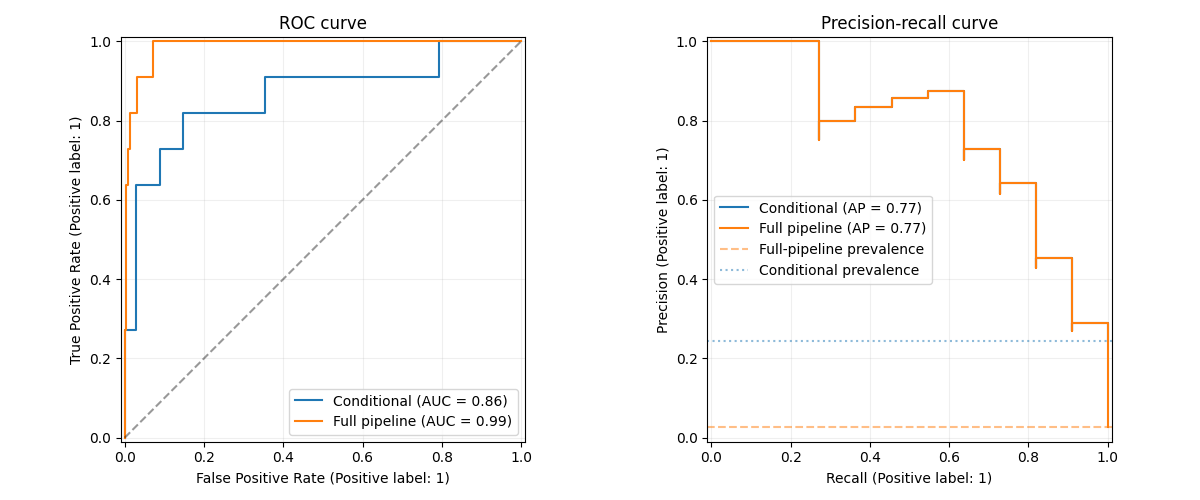

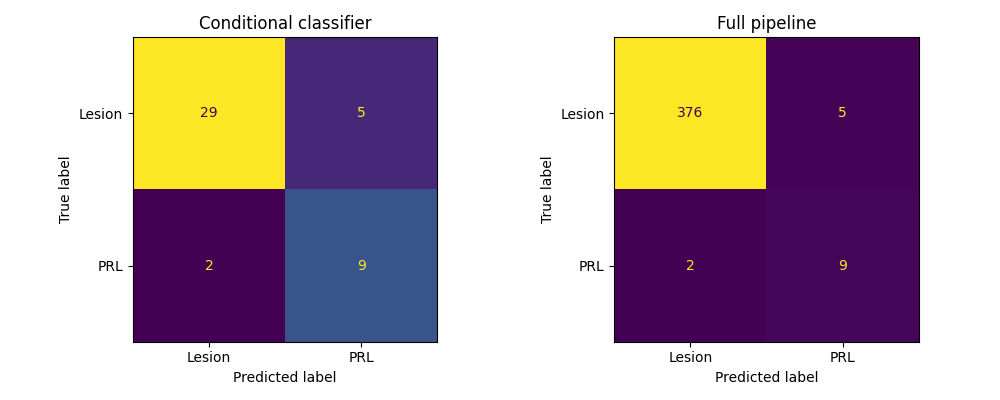

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    auc,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# %% Configuration

TARGET = "case_type"
POS_LABEL = "PRL"
SCREEN_COL = "has_iron_infer"

TEST_SIZE = 0.10
RANDOM_STATE = 42

FEATURES = [
    "rim_volume_infer",
    "rim_hull_volume_infer",
    "rim_sphere_radius_infer",
    "pca_size",
    "pca_sphericity",
    "pca_planarity",
    "pca_linearity",
    "mean_radius",
    "std_radius",
    "min_radius",
    "max_radius",
    "radial_cv",
]

# %% Prepare data

# Keep lesion identifiers as the DataFrame index throughout.
data = df.set_index(["subid", "lesion_index"], verify_integrity=True).copy()

# Only evaluate lesions with a known ground-truth class.
data = data.loc[data[TARGET].isin(["PRL", "Lesion"])].copy()

data["y_true"] = data[TARGET].eq(POS_LABEL).astype(int)
data[SCREEN_COL] = data[SCREEN_COL].fillna(False).astype(bool)

# Separate lesions by SegResNet screening result.
screened_in = data.loc[data[SCREEN_COL]]
screened_out = data.loc[~data[SCREEN_COL]]

print(f"All lesions:  {len(data)} ({data.y_true.sum()} PRLs)")
print(f"Screened in:  {len(screened_in)} ({screened_in.y_true.sum()} PRLs)")
print(f"Screened out: {len(screened_out)} ({screened_out.y_true.sum()} PRLs)")

screen_sensitivity = screened_in.y_true.sum() / data.y_true.sum()
print(f"Rim-screen sensitivity: {screen_sensitivity:.1%}")

# %% Split and train

# Split the DataFrames directly: their MultiIndex is retained.
train_df, test_df = train_test_split(
    screened_in,
    test_size=TEST_SIZE,
    stratify=screened_in["y_true"],
    random_state=RANDOM_STATE,
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

model.fit(train_df[FEATURES], train_df["y_true"])

print(f"\nTrain: {len(train_df)} ({train_df.y_true.sum()} PRLs)")
print(f"Test:  {len(test_df)} ({test_df.y_true.sum()} PRLs)")

# %% Conditional classifier predictions

# Predictions for lesions that passed the rim screen.
conditional_test = test_df[["y_true"]].copy()
conditional_test["score"] = model.predict_proba(test_df[FEATURES])[:, 1]

# %% Full-pipeline predictions

# Sample the same fraction of screened-out lesions.
rejected_test = screened_out.sample(
    frac=TEST_SIZE,
    random_state=RANDOM_STATE,
)[["y_true"]].copy()

# Hard screening rule: lesions without predicted rims receive score 0.
rejected_test["score"] = 0.0

# Combine both sets while preserving (subid, lesion_index).
pipeline_test = pd.concat([conditional_test, rejected_test])
pipeline_test = pipeline_test.sort_index()

print(
    f"\nFull pipeline test: {len(pipeline_test)} lesions "
    f"({pipeline_test.y_true.sum()} PRLs)"
)

print(
    f"Rejected PRLs in test: {rejected_test.y_true.sum()} "
    f"out of {len(rejected_test)} rejected lesions"
)

# %% Metrics

def evaluate_predictions(predictions, threshold=0.5):
    y_true = predictions["y_true"]
    y_score = predictions["score"]
    y_pred = (y_score >= threshold).astype(int)

    precision, recall, _ = precision_recall_curve(y_true, y_score)

    return {
        "n": len(predictions),
        "n_prl": int(y_true.sum()),
        "prevalence": y_true.mean(),
        "roc_auc": roc_auc_score(y_true, y_score),
        "average_precision": average_precision_score(y_true, y_score),
        "pr_auc": auc(recall, precision),
        "sensitivity": ((y_pred == 1) & (y_true == 1)).sum() / y_true.sum(),
        "specificity": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }


metrics = pd.DataFrame({
    "Conditional classifier": evaluate_predictions(conditional_test),
    "Full pipeline": evaluate_predictions(pipeline_test),
}).T

display(metrics.round(3))

print("\n--- Conditional classifier ---")
print(classification_report(
    conditional_test.y_true,
    (conditional_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

print("\n--- Full pipeline ---")
print(classification_report(
    pipeline_test.y_true,
    (pipeline_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

# %% ROC and precision-recall curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, predictions, color in [
    ("Conditional", conditional_test, "C0"),
    ("Full pipeline", pipeline_test, "C1"),
]:
    RocCurveDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        color=color,
        ax=axes[0],
    )

    PrecisionRecallDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        color=color,
        ax=axes[1],
    )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curve")
axes[0].grid(alpha=0.2)

axes[1].axhline(
    pipeline_test.y_true.mean(),
    color="C1",
    linestyle="--",
    alpha=0.5,
    label="Full-pipeline prevalence",
)
axes[1].axhline(
    conditional_test.y_true.mean(),
    color="C0",
    linestyle=":",
    alpha=0.5,
    label="Conditional prevalence",
)
axes[1].set_title("Precision-recall curve")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

# %% Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, predictions) in zip(
    axes,
    [
        ("Conditional classifier", conditional_test),
        ("Full pipeline", pipeline_test),
    ],
):
    cm = confusion_matrix(
        predictions.y_true,
        (predictions.score >= 0.5).astype(int),
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=["Lesion", "PRL"],
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()


All lesions:  3912 (116 PRLs)
Screened in:  442 (111 PRLs)
Screened out: 3470 (5 PRLs)
Rim-screen sensitivity: 95.7%

Train: 397 (100 PRLs)
Test:  45 (11 PRLs)

Full pipeline test: 392 lesions (11 PRLs)
Rejected PRLs in test: 0 out of 347 rejected lesions


,n,n_prl,prevalence,roc_auc,average_precision,pr_auc,sensitivity,specificity
Conditional classifier,45.0,11.0,0.244,0.826,0.725,0.715,0.727,0.824
Full pipeline,392.0,11.0,0.028,0.984,0.725,0.715,0.727,0.984



--- Conditional classifier ---
              precision    recall  f1-score   support

      Lesion       0.90      0.82      0.86        34
         PRL       0.57      0.73      0.64        11

    accuracy                           0.80        45
   macro avg       0.74      0.78      0.75        45
weighted avg       0.82      0.80      0.81        45


--- Full pipeline ---
              precision    recall  f1-score   support

      Lesion       0.99      0.98      0.99       381
         PRL       0.57      0.73      0.64        11

    accuracy                           0.98       392
   macro avg       0.78      0.86      0.81       392
weighted avg       0.98      0.98      0.98       392



/home/srs-9/.virtualenvs/monai/lib/python3.13/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/home/srs-9/.virtualenvs/monai/lib/python3.13/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


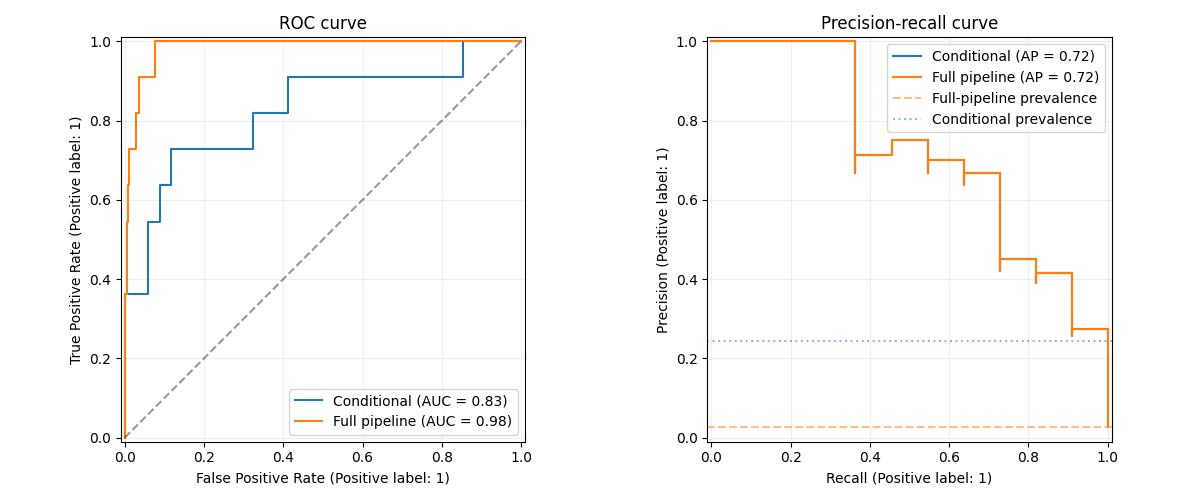

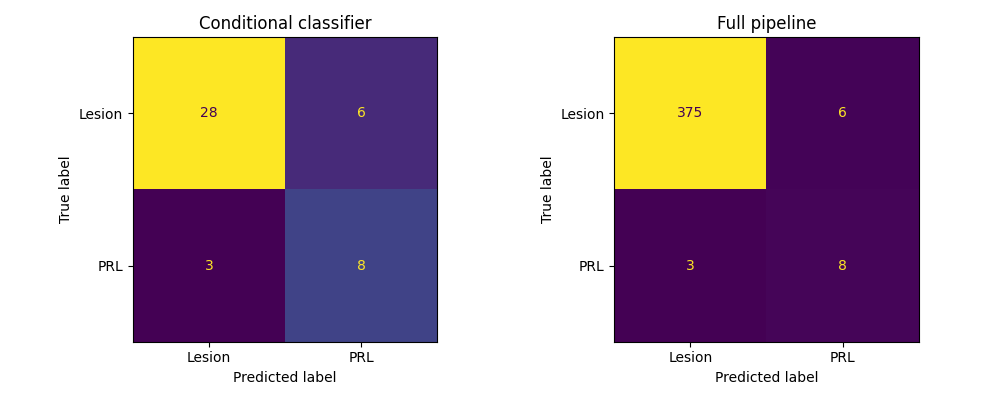

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    auc,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# %% Configuration

TARGET = "case_type"
POS_LABEL = "PRL"
SCREEN_COL = "has_iron_infer"

TEST_SIZE = 0.10
RANDOM_STATE = 42

FEATURES = [col for col in df.columns if 'shape_' in col] + [
    "rim_volume_infer",
    "rim_hull_volume_infer",
    "rim_sphere_radius_infer",
    "pca_size",
    "pca_sphericity",
    "pca_planarity",
    "pca_linearity",
    "mean_radius",
    "std_radius",
    "min_radius",
    "max_radius",
    "radial_cv",
]

# %% Prepare data

# Keep lesion identifiers as the DataFrame index throughout.
data = df.set_index(["subid", "lesion_index"], verify_integrity=True).copy()

# Only evaluate lesions with a known ground-truth class.
data = data.loc[data[TARGET].isin(["PRL", "Lesion"])].copy()

data["y_true"] = data[TARGET].eq(POS_LABEL).astype(int)
data[SCREEN_COL] = data[SCREEN_COL].fillna(False).astype(bool)

# Separate lesions by SegResNet screening result.
screened_in = data.loc[data[SCREEN_COL]]
screened_out = data.loc[~data[SCREEN_COL]]

print(f"All lesions:  {len(data)} ({data.y_true.sum()} PRLs)")
print(f"Screened in:  {len(screened_in)} ({screened_in.y_true.sum()} PRLs)")
print(f"Screened out: {len(screened_out)} ({screened_out.y_true.sum()} PRLs)")

screen_sensitivity = screened_in.y_true.sum() / data.y_true.sum()
print(f"Rim-screen sensitivity: {screen_sensitivity:.1%}")

# %% Split and train

# Split the DataFrames directly: their MultiIndex is retained.
train_df, test_df = train_test_split(
    screened_in,
    test_size=TEST_SIZE,
    stratify=screened_in["y_true"],
    random_state=RANDOM_STATE,
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

model.fit(train_df[FEATURES], train_df["y_true"])

print(f"\nTrain: {len(train_df)} ({train_df.y_true.sum()} PRLs)")
print(f"Test:  {len(test_df)} ({test_df.y_true.sum()} PRLs)")

# %% Conditional classifier predictions

# Predictions for lesions that passed the rim screen.
conditional_test = test_df[["y_true"]].copy()
conditional_test["score"] = model.predict_proba(test_df[FEATURES])[:, 1]

# %% Full-pipeline predictions

# Sample the same fraction of screened-out lesions.
rejected_test = screened_out.sample(
    frac=TEST_SIZE,
    random_state=RANDOM_STATE,
)[["y_true"]].copy()

# Hard screening rule: lesions without predicted rims receive score 0.
rejected_test["score"] = 0.0

# Combine both sets while preserving (subid, lesion_index).
pipeline_test = pd.concat([conditional_test, rejected_test])
pipeline_test = pipeline_test.sort_index()

print(
    f"\nFull pipeline test: {len(pipeline_test)} lesions "
    f"({pipeline_test.y_true.sum()} PRLs)"
)

print(
    f"Rejected PRLs in test: {rejected_test.y_true.sum()} "
    f"out of {len(rejected_test)} rejected lesions"
)

# %% Metrics

def evaluate_predictions(predictions, threshold=0.5):
    y_true = predictions["y_true"]
    y_score = predictions["score"]
    y_pred = (y_score >= threshold).astype(int)

    precision, recall, _ = precision_recall_curve(y_true, y_score)

    return {
        "n": len(predictions),
        "n_prl": int(y_true.sum()),
        "prevalence": y_true.mean(),
        "roc_auc": roc_auc_score(y_true, y_score),
        "average_precision": average_precision_score(y_true, y_score),
        "pr_auc": auc(recall, precision),
        "sensitivity": ((y_pred == 1) & (y_true == 1)).sum() / y_true.sum(),
        "specificity": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }


metrics = pd.DataFrame({
    "Conditional classifier": evaluate_predictions(conditional_test),
    "Full pipeline": evaluate_predictions(pipeline_test),
}).T

display(metrics.round(3))

print("\n--- Conditional classifier ---")
print(classification_report(
    conditional_test.y_true,
    (conditional_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

print("\n--- Full pipeline ---")
print(classification_report(
    pipeline_test.y_true,
    (pipeline_test.score >= 0.5).astype(int),
    target_names=["Lesion", "PRL"],
    zero_division=0,
))

# %% ROC and precision-recall curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, predictions, color in [
    ("Conditional", conditional_test, "C0"),
    ("Full pipeline", pipeline_test, "C1"),
]:
    RocCurveDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        color=color,
        ax=axes[0],
    )

    PrecisionRecallDisplay.from_predictions(
        predictions.y_true,
        predictions.score,
        name=name,
        color=color,
        ax=axes[1],
    )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curve")
axes[0].grid(alpha=0.2)

axes[1].axhline(
    pipeline_test.y_true.mean(),
    color="C1",
    linestyle="--",
    alpha=0.5,
    label="Full-pipeline prevalence",
)
axes[1].axhline(
    conditional_test.y_true.mean(),
    color="C0",
    linestyle=":",
    alpha=0.5,
    label="Conditional prevalence",
)
axes[1].set_title("Precision-recall curve")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

# %% Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, predictions) in zip(
    axes,
    [
        ("Conditional classifier", conditional_test),
        ("Full pipeline", pipeline_test),
    ],
):
    cm = confusion_matrix(
        predictions.y_true,
        (predictions.score >= 0.5).astype(int),
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=["Lesion", "PRL"],
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay,
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [11]:
TARGET = "case_type"        # "PRL" or "Lesion"
POS_LABEL = "PRL"

TEST_SIZE = 0.25            # fraction held out
RANDOM_STATE = 42
CV_FOLDS = 5

# FEATURES = [col for col in all_features.columns if 'shape' in col]
FEATURES = [
    "rim_volume_infer",
    "rim_hull_volume_infer",
    "rim_sphere_radius_infer",
    "pca_size",
    "pca_sphericity",

    "pca_planarity",
    "pca_linearity",
    "mean_radius",
    "std_radius",
    "min_radius",
    "max_radius",
    "radial_cv",
]

In [24]:
TEST_SIZE = 0.1            # fraction held out

model_df = df[df.has_iron_infer].copy()
print(f"Loaded {len(model_df)} rows | {model_df[TARGET].value_counts().to_dict()}")

X = model_df[['subid', 'lesion_index']+FEATURES].values
y = (model_df[TARGET] == POS_LABEL).astype(int).values   # 1 = PRL, 0 = Lesion

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(y_train)} ({y_train.sum()} PRL) | Test: {len(y_test)} ({y_test.sum()} PRL)")

index_train = X_train[:, :2]
index_test = X_test[:, :2]
X_train = X_train[:, 2:]
X_test = X_test[:, 2:]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),   # hull/sphere NaN when <4 rim voxels
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",    # important: 48 PRL vs ~117 Lesion
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

model.fit(X_train, y_train)

Loaded 442 rows | {'Lesion': 331, 'PRL': 111}
Train: 397 (100 PRL) | Test: 45 (11 PRL)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'constant'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",0
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If


--- Test set ---
              precision    recall  f1-score   support

      Lesion       0.94      0.85      0.89        34
         PRL       0.64      0.82      0.72        11

    accuracy                           0.84        45
   macro avg       0.79      0.84      0.81        45
weighted avg       0.86      0.84      0.85        45

ROC-AUC: 0.864


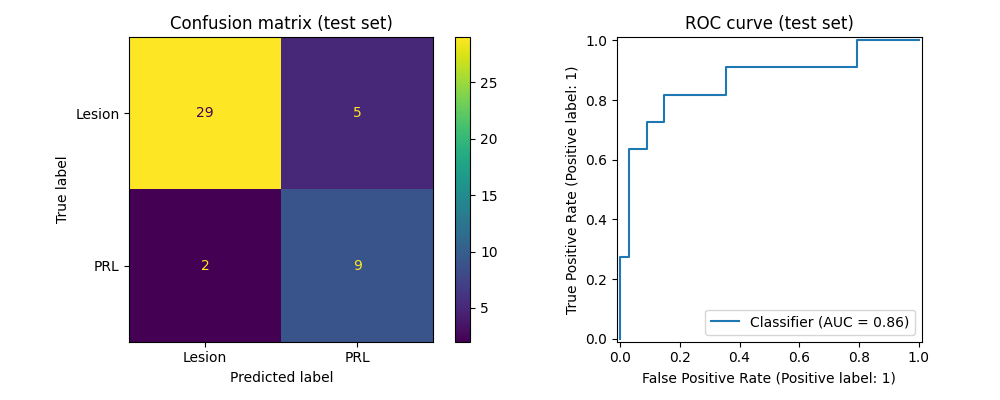

In [25]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\n--- Test set ---")
print(classification_report(y_test, y_pred, target_names=["Lesion", "PRL"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Lesion", "PRL"]).plot(ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, y_prob, pos_label=1, ax=axes[1])
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

In [ ]:
df = screened_cases.reset_index().merge(
    feature_df,
    on=["subid", "lesion_index"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_y")
)
df = df[df.split == "testing"]
df